In [1]:
print("Vrinda Store Project - Python Environment Ready")

Vrinda Store Project - Python Environment Ready


In [2]:
import sqlalchemy
import pymysql

print("SQLAlchemy:", sqlalchemy.__version__)
print("MySQL driver: Ready")

SQLAlchemy: 2.1.4
MySQL driver: Ready


In [3]:
%pip install sqlalchemy pymysql

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [27]:

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

password = getpass("Enter MySQL password: ")

connection_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=password,
    host="localhost",
    port=3306,
    database="vrinda_store_db"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("Connection test:", connection.execute(text("SELECT 1")).scalar())


Connection test: 1


In [6]:

import pandas as pd

query = "SELECT * FROM vrinda_store_sales"

df = pd.read_sql(query, engine)

print("Data extraction successful!")
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()


Data extraction successful!
Rows and columns: (31047, 21)

Column names:
['record_index', 'order_id', 'cust_id', 'gender', 'age', 'age_group', 'order_date', 'month', 'status', 'channel', 'sku', 'category', 'size', 'qty', 'currency', 'amount', 'ship_city', 'ship_state', 'ship_postal_code', 'ship_country', 'b2b']


,record_index,order_id,cust_id,gender,age,age_group,order_date,month,status,channel,...,category,size,qty,currency,amount,ship_city,ship_state,ship_postal_code,ship_country,b2b
0,1,171-1029312-3038738,1029312,Women,44,Adult,2022-12-04,December,Delivered,Myntra,...,kurta,XXL,1,INR,376.0,MOHALI,PUNJAB,140301,IN,0
1,2,405-2183842-2225946,2183842,Women,29,Teenager,2022-12-04,December,Delivered,Ajio,...,Set,L,1,INR,1449.0,GURUGRAM,HARYANA,122002,IN,0
2,3,171-1641533-8921966,1641533,Women,67,Senior,2022-12-04,December,Delivered,Myntra,...,Set,S,1,INR,453.0,KOLKATA,WEST BENGAL,700029,IN,0
3,4,404-7490807-6300351,7490807,Women,20,Teenager,2022-12-04,December,Delivered,Amazon,...,Set,M,1,INR,729.0,THANJAVUR,TAMIL NADU,613007,IN,0
4,5,403-9293516-4577154,9293516,Women,62,Senior,2022-12-04,December,Delivered,Myntra,...,kurta,XXL,1,INR,544.0,GURUGRAM,HARYANA,122001,IN,0


In [7]:

print("Dataset dimensions:", df.shape)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Duplicate records:", df.duplicated().sum())
print("Missing values across all columns:", df.isna().sum().sum())


Dataset dimensions: (31047, 21)
Total rows: 31047
Total columns: 21
Duplicate records: 0
Missing values across all columns: 0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   record_index      31047 non-null  int64  
 1   order_id          31047 non-null  str    
 2   cust_id           31047 non-null  int64  
 3   gender            31047 non-null  str    
 4   age               31047 non-null  int64  
 5   age_group         31047 non-null  str    
 6   order_date        31047 non-null  object 
 7   month             31047 non-null  str    
 8   status            31047 non-null  str    
 9   channel           31047 non-null  str    
 10  sku               31047 non-null  str    
 11  category          31047 non-null  str    
 12  size              31047 non-null  str    
 13  qty               31047 non-null  int64  
 14  currency          31047 non-null  str    
 15  amount            31047 non-null  float64
 16  ship_city         31047 non-null  str    
 17  ship

In [9]:
import numpy as np

amount_array = np.array(df["amount"])

print(type(amount_array))
print(amount_array.shape)

<class 'numpy.ndarray'>
(31047,)


In [10]:
discounted_amount = amount_array *0.90   


print(discounted_amount[:5])

[ 338.4 1304.1  407.7  656.1  489.6]


In [11]:
conditions = [
    df["amount"] > 1000,
    (df["amount"] > 500) & (df["amount"] <= 1000)
]

choices = ["High", "Medium"]

amount_category = np.select(
    conditions,
    choices,
    default="Low"
)

print(amount_category[:10])

['Low' 'High' 'Low' 'Medium' 'Medium' 'Medium' 'Medium' 'Low' 'Low'
 'Medium']


In [12]:
unique_categories, category_counts = np.unique(
    amount_category,
    return_counts=True
)

for category, count in zip(unique_categories, category_counts):
    print(category, ":", count)

High : 3772
Low : 9371
Medium : 17904


In [13]:
total_records = len(amount_category)

category_percentage = (category_counts / total_records) * 100

category_percentage = np.round(category_percentage, 2)

for category, percentage in zip(unique_categories, category_percentage):
    print(f"{category}: {percentage}%")

High: 12.15%
Low: 30.18%
Medium: 57.67%


In [14]:
total_records = len(df)
total_revenue = df["amount"].sum()

print("Total Records:", total_records)
print("Total Revenue:", round(total_revenue, 2))

Total Records: 31047
Total Revenue: 21176377.0


In [15]:
gender_revenue = (
    df.groupby("gender", as_index=False)["amount"]
      .sum()
      .rename(columns={"amount": "total_revenue"})
)

print(gender_revenue)

  gender  total_revenue
0    Men      7613604.0
1  Women     13562773.0


In [16]:
gender_revenue = (
    df.groupby("ship_state", as_index=False)["amount"]
      .sum()
      .rename(columns={"amount": "total_revenue"})
      .sort_values(by="total_revenue", ascending=False))

print(gender_revenue)

            ship_state  total_revenue
25         MAHARASHTRA      2990221.0
21           KARNATAKA      2646358.0
43       UTTAR PRADESH      2104659.0
41           TELANGANA      1712439.0
40          TAMIL NADU      1678877.0
12               DELHI      1248111.0
22              KERALA      1008940.0
45         WEST BENGAL       922444.0
1       ANDHRA PRADESH       918499.0
17             HARYANA       813320.0
15             GUJARAT       715563.0
24      MADHYA PRADESH       564026.0
37           RAJASTHAN       547360.0
6                BIHAR       440051.0
33              ODISHA       414840.0
35              PUNJAB       361969.0
44         UTTARAKHAND       327179.0
3                ASSAM       326423.0
20           JHARKHAND       255054.0
14                 GOA       180029.0
9         CHHATTISGARH       174531.0
19     JAMMU & KASHMIR       158736.0
18    HIMACHAL PRADESH       146246.0
26             MANIPUR        78526.0
8           CHANDIGARH        60726.0
38          

In [17]:
print(sorted(df["ship_state"].dropna().unique()))

['ANDAMAN & NICOBAR ', 'ANDHRA PRADESH', 'ARUNACHAL PRADESH', 'ASSAM', 'Arunachal Pradesh', 'Arunachal pradesh', 'BIHAR', 'Bihar', 'CHANDIGARH', 'CHHATTISGARH', 'Chandigarh', 'DADRA AND NAGAR', 'DELHI', 'Delhi', 'GOA', 'GUJARAT', 'Goa', 'HARYANA', 'HIMACHAL PRADESH', 'JAMMU & KASHMIR', 'JHARKHAND', 'KARNATAKA', 'KERALA', 'LADAKH', 'MADHYA PRADESH', 'MAHARASHTRA', 'MANIPUR', 'MEGHALAYA', 'MIZORAM', 'Manipur', 'NAGALAND', 'Nagaland', 'New Delhi', 'ODISHA', 'PUDUCHERRY', 'PUNJAB', 'Punjab', 'RAJASTHAN', 'SIKKIM', 'Sikkim', 'TAMIL NADU', 'TELANGANA', 'TRIPURA', 'UTTAR PRADESH', 'UTTARAKHAND', 'WEST BENGAL', 'bihar', 'delhi', 'goa', 'punjab']


In [18]:
df["ship_state_clean"] = (
    df["ship_state"]
    .str.strip()
    .str.upper()
)

print(sorted(df["ship_state_clean"].dropna().unique()))

['ANDAMAN & NICOBAR', 'ANDHRA PRADESH', 'ARUNACHAL PRADESH', 'ASSAM', 'BIHAR', 'CHANDIGARH', 'CHHATTISGARH', 'DADRA AND NAGAR', 'DELHI', 'GOA', 'GUJARAT', 'HARYANA', 'HIMACHAL PRADESH', 'JAMMU & KASHMIR', 'JHARKHAND', 'KARNATAKA', 'KERALA', 'LADAKH', 'MADHYA PRADESH', 'MAHARASHTRA', 'MANIPUR', 'MEGHALAYA', 'MIZORAM', 'NAGALAND', 'NEW DELHI', 'ODISHA', 'PUDUCHERRY', 'PUNJAB', 'RAJASTHAN', 'SIKKIM', 'TAMIL NADU', 'TELANGANA', 'TRIPURA', 'UTTAR PRADESH', 'UTTARAKHAND', 'WEST BENGAL']


In [26]:

# Step 1: State names clean karo
df["ship_state_clean"] = (
    df["ship_state"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Step 2: Delhi aur New Delhi ko ek state mein combine karo
df["ship_state_final"] = df["ship_state_clean"].replace({
    "NEW DELHI": "DELHI"
})

# Step 3: State-wise revenue calculate karo
state_revenue = (
    df.groupby("ship_state_final", as_index=False)["amount"]
      .sum()
      .rename(columns={"amount": "total_revenue"})
      .sort_values(by="total_revenue", ascending=False)
)

# Step 4: Top 10 states
print("TOP 10 STATES BY REVENUE")
display(state_revenue.head(10))

# Step 5: Delhi revenue verify karo
print("\nDELHI REVENUE AFTER COMBINING NEW DELHI")
display(
    state_revenue[
        state_revenue["ship_state_final"] == "DELHI"
    ]
)

# Step 6: Total revenue reconciliation
print("\nTOTAL REVENUE CHECK")
print("Total records:", len(df))
print("Original total revenue:", df["amount"].sum())
print("State-wise revenue total:", state_revenue["total_revenue"].sum())
print(
    "Revenue difference:",
    df["amount"].sum() - state_revenue["total_revenue"].sum()
)


TOP 10 STATES BY REVENUE


,ship_state_final,total_revenue
19,MAHARASHTRA,2990221.0
15,KARNATAKA,2646358.0
32,UTTAR PRADESH,2104659.0
30,TELANGANA,1712439.0
29,TAMIL NADU,1678877.0
8,DELHI,1274750.0
16,KERALA,1008940.0
34,WEST BENGAL,922444.0
1,ANDHRA PRADESH,918499.0
11,HARYANA,813320.0



DELHI REVENUE AFTER COMBINING NEW DELHI


,ship_state_final,total_revenue
8,DELHI,1274750.0



TOTAL REVENUE CHECK
Total records: 31047
Original total revenue: 21176377.0
State-wise revenue total: 21176377.0
Revenue difference: 0.0


In [20]:
# Create a new column; original ship_state_clean remains unchanged
df["ship_state_final"] = df["ship_state_clean"].replace({
    "NEW DELHI": "DELHI"
})

# Recalculate state-wise revenue
state_revenue_final = (
    df.groupby("ship_state_final", as_index=False)["amount"]
      .sum()
      .rename(columns={"amount": "total_revenue"})
      .sort_values("total_revenue", ascending=False)
)

# Display Delhi revenue after merging
display(
    state_revenue_final[
        state_revenue_final["ship_state_final"] == "DELHI"
    ]
)

# Display top 10 states
display(state_revenue_final.head(10))

# Verify total revenue is unchanged
print("Original total revenue:", df["amount"].sum())
print("Reconciled state revenue:", state_revenue_final["total_revenue"].sum())

,ship_state_final,total_revenue
8,DELHI,1274750.0


,ship_state_final,total_revenue
19,MAHARASHTRA,2990221.0
15,KARNATAKA,2646358.0
32,UTTAR PRADESH,2104659.0
30,TELANGANA,1712439.0
29,TAMIL NADU,1678877.0
8,DELHI,1274750.0
16,KERALA,1008940.0
34,WEST BENGAL,922444.0
1,ANDHRA PRADESH,918499.0
11,HARYANA,813320.0


Original total revenue: 21176377.0
Reconciled state revenue: 21176377.0


In [21]:
# Step 1: Define data-quality conditions
conditions = [
    (df["qty"] <= 0) | (df["amount"] < 0)
]

# Step 2: Assign quality flags using NumPy
choices = ["Review"]

df["quality_flag"] = np.select(
    conditions,
    choices,
    default="Valid"
)

# Step 3: Count records in each category
quality_summary = (
    df["quality_flag"]
    .value_counts()
    .rename_axis("quality_flag")
    .reset_index(name="total_records")
)

display(quality_summary)

# Step 4: Reconcile record counts
print("Original records:", len(df))
print("Classified records:", df["quality_flag"].count())
print("Valid records:", (df["quality_flag"] == "Valid").sum())
print("Review records:", (df["quality_flag"] == "Review").sum())
print("Total classified:", df["quality_flag"].isin(["Valid", "Review"]).sum())

,quality_flag,total_records
0,Valid,31047


Original records: 31047
Classified records: 31047
Valid records: 31047
Review records: 0
Total classified: 31047


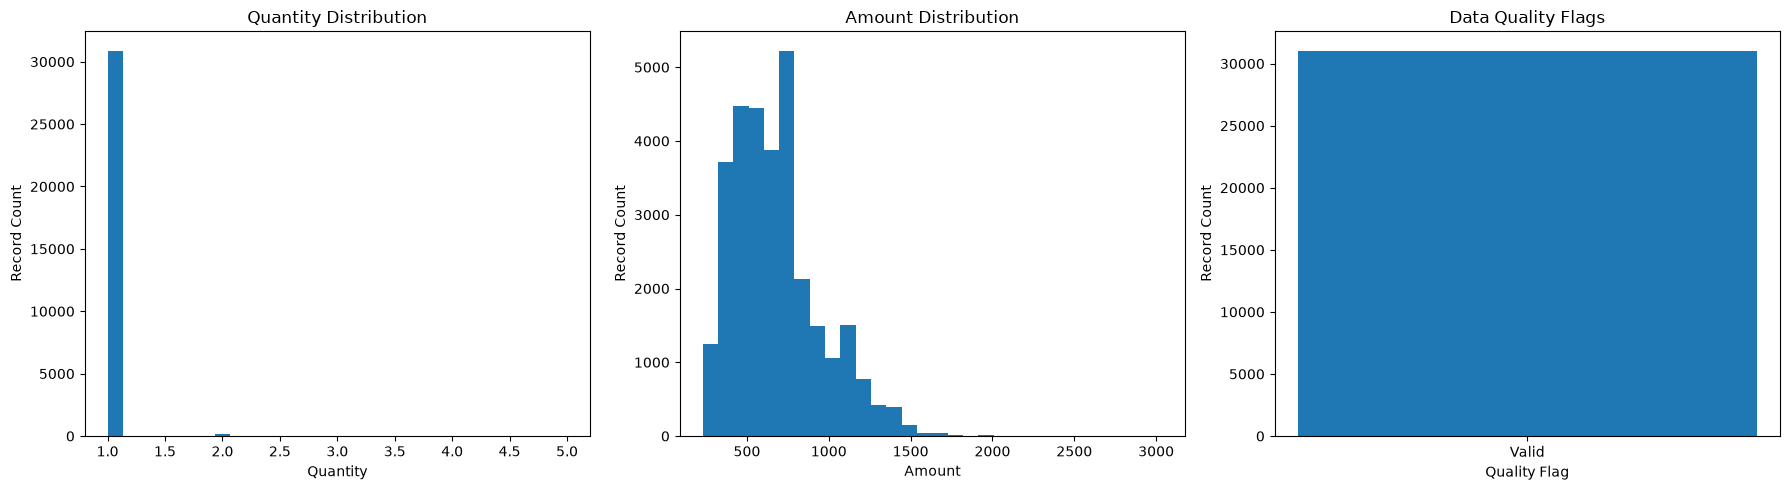

In [22]:
import matplotlib.pyplot as plt

# Create 3 diagnostic subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Quantity distribution
axes[0].hist(df["qty"].dropna(), bins=30)
axes[0].set_title("Quantity Distribution")
axes[0].set_xlabel("Quantity")
axes[0].set_ylabel("Record Count")

# Chart 2: Amount distribution
axes[1].hist(df["amount"].dropna(), bins=30)
axes[1].set_title("Amount Distribution")
axes[1].set_xlabel("Amount")
axes[1].set_ylabel("Record Count")

# Chart 3: Data-quality flag counts
quality_counts = df["quality_flag"].value_counts()

axes[2].bar(
    quality_counts.index,
    quality_counts.values
)
axes[2].set_title("Data Quality Flags")
axes[2].set_xlabel("Quality Flag")
axes[2].set_ylabel("Record Count")

# Improve layout and display
plt.tight_layout()
plt.show()

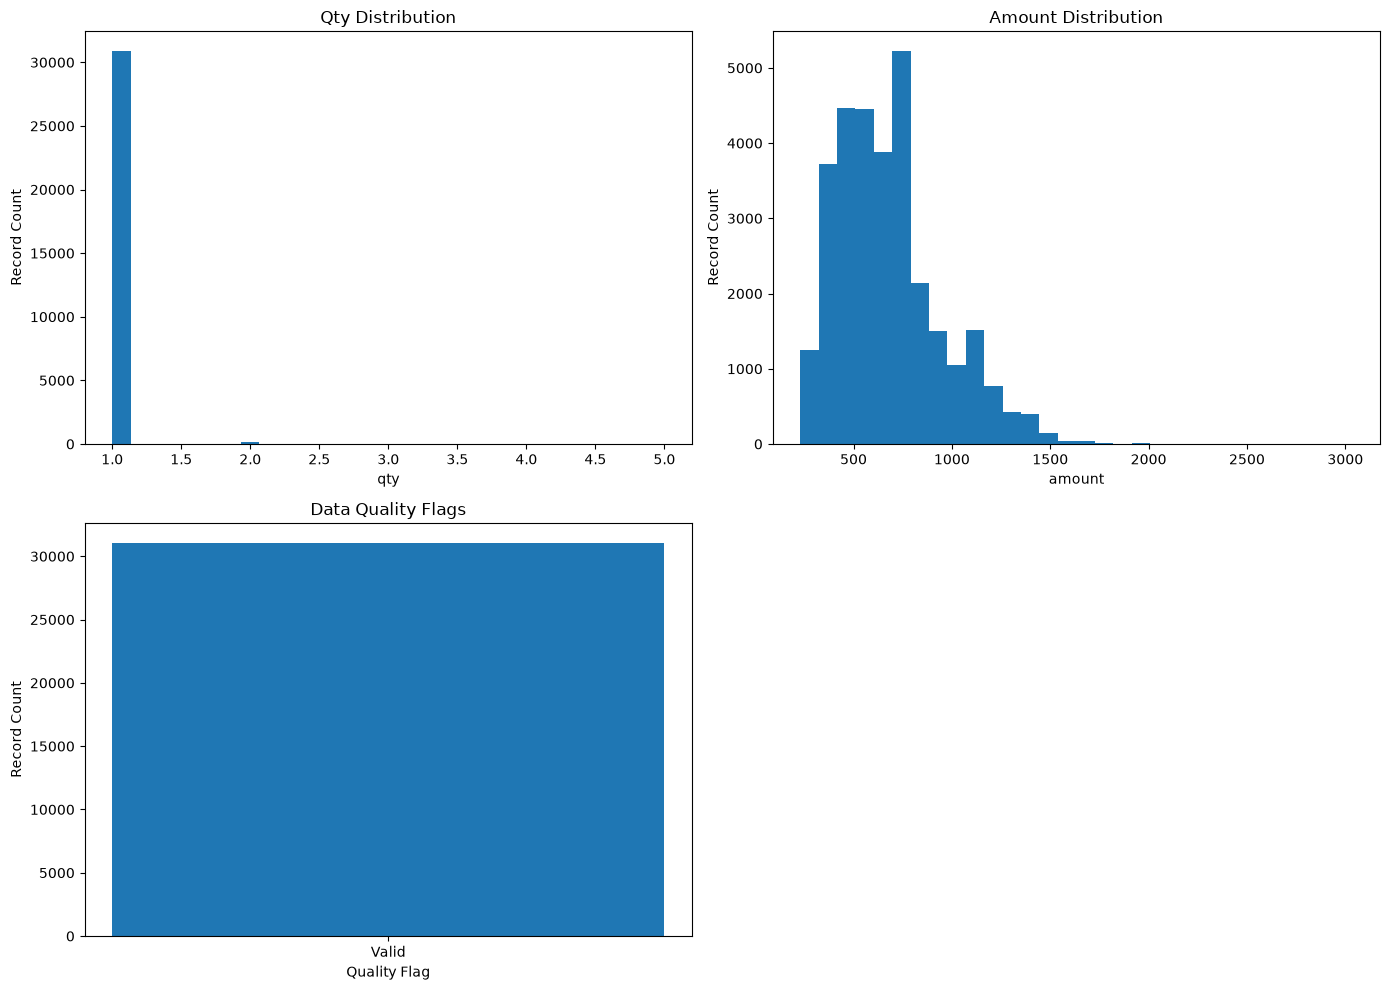

Missing qty: 0
Missing amount: 0
Non-positive quantity: 0
Negative amount: 0


In [23]:
import matplotlib.pyplot as plt
import math

# Define diagnostic columns
diagnostic_columns = ["qty", "amount"]
n_charts = len(diagnostic_columns) + 1

# Dynamic subplot layout
n_cols = 2
n_rows = math.ceil(n_charts / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(14, 5 * n_rows)
)

axes = axes.flatten()

# Quantity and amount distributions
for i, column in enumerate(diagnostic_columns):
    axes[i].hist(df[column].dropna(), bins=30)
    axes[i].set_title(f"{column.title()} Distribution")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Record Count")

# Data-quality flag counts
quality_counts = df["quality_flag"].value_counts()

axes[2].bar(quality_counts.index, quality_counts.values)
axes[2].set_title("Data Quality Flags")
axes[2].set_xlabel("Quality Flag")
axes[2].set_ylabel("Record Count")

# Remove any unused subplot
for i in range(n_charts, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# Diagnostic checks
print("Missing qty:", df["qty"].isna().sum())
print("Missing amount:", df["amount"].isna().sum())
print("Non-positive quantity:", (df["qty"] <= 0).sum())
print("Negative amount:", (df["amount"] < 0).sum())

In [24]:
# Final Python reconciliation against Excel baseline

checks = {
    "Total records": len(df),
    "Total revenue": round(df["amount"].sum(), 2),
    "Men revenue": round(
        df.loc[df["gender"] == "Men", "amount"].sum(), 2
    ),
    "Women revenue": round(
        df.loc[df["gender"] == "Women", "amount"].sum(), 2
    ),
    "Amazon revenue": round(
        df.loc[df["channel"] == "Amazon", "amount"].sum(), 2
    ),
    "Set category revenue": round(
        df.loc[df["category"] == "Set", "amount"].sum(), 2
    ),
    "Maharashtra revenue": round(
        df.loc[df["ship_state_final"] == "MAHARASHTRA", "amount"].sum(), 2
    ),
    "Delhi revenue": round(
        df.loc[df["ship_state_final"] == "DELHI", "amount"].sum(), 2
    )
}

for metric, value in checks.items():
    print(f"{metric}: {value}")

print("\nDATA QUALITY CHECKS")
print("Missing qty:", df["qty"].isna().sum())
print("Missing amount:", df["amount"].isna().sum())
print("Non-positive quantity:", (df["qty"] <= 0).sum())
print("Negative amount:", (df["amount"] < 0).sum())
print("Valid records:", (df["quality_flag"] == "Valid").sum())
print("Review records:", (df["quality_flag"] == "Review").sum())

Total records: 31047
Total revenue: 21176377.0
Men revenue: 7613604.0
Women revenue: 13562773.0
Amazon revenue: 7519933.0
Set category revenue: 10507546.0
Maharashtra revenue: 2990221.0
Delhi revenue: 1274750.0

DATA QUALITY CHECKS
Missing qty: 0
Missing amount: 0
Non-positive quantity: 0
Negative amount: 0
Valid records: 31047
Review records: 0


In [25]:
import pandas as pd
import numpy as np

# 1. Define verified Excel baseline
baseline = {
    "Total records": 31047,
    "Total revenue": 21176377.00,
    "Men revenue": 7613604.00,
    "Women revenue": 13562773.00,
    "Amazon revenue": 7519933.00,
    "Set category revenue": 10507546.00,
    "Maharashtra revenue": 2990221.00,
    "Delhi revenue": 1274750.00
}

# 2. Calculate metrics from the current Python DataFrame
actual = {
    "Total records": len(df),
    "Total revenue": df["amount"].sum(),
    "Men revenue": df.loc[df["gender"] == "Men", "amount"].sum(),
    "Women revenue": df.loc[df["gender"] == "Women", "amount"].sum(),
    "Amazon revenue": df.loc[df["channel"] == "Amazon", "amount"].sum(),
    "Set category revenue": df.loc[df["category"] == "Set", "amount"].sum(),
    "Maharashtra revenue": df.loc[
        df["ship_state_final"] == "MAHARASHTRA", "amount"
    ].sum(),
    "Delhi revenue": df.loc[
        df["ship_state_final"] == "DELHI", "amount"
    ].sum()
}

# 3. Create reconciliation table
reconciliation = pd.DataFrame({
    "Metric": list(baseline.keys()),
    "Excel_Baseline": list(baseline.values()),
    "Python_Result": [actual[k] for k in baseline]
})

reconciliation["Difference"] = (
    reconciliation["Python_Result"]
    - reconciliation["Excel_Baseline"]
).round(2)

reconciliation["Status"] = np.where(
    reconciliation["Difference"].abs() < 0.01,
    "MATCH",
    "INVESTIGATE"
)

display(reconciliation)

# 4. Final data-quality summary
quality_report = pd.DataFrame({
    "Check": [
        "Total records",
        "Missing quantity",
        "Missing amount",
        "Non-positive quantity",
        "Negative amount",
        "Valid records",
        "Review records",
        "Full-row duplicates"
    ],
    "Result": [
        len(df),
        df["qty"].isna().sum(),
        df["amount"].isna().sum(),
        (df["qty"] <= 0).sum(),
        (df["amount"] < 0).sum(),
        (df["quality_flag"] == "Valid").sum(),
        (df["quality_flag"] == "Review").sum(),
        df.duplicated().sum()
    ]
})

print("DATA QUALITY REPORT")
display(quality_report)

# 5. Overall reconciliation verdict
print("All baseline metrics match:",
      reconciliation["Status"].eq("MATCH").all())

print("Total revenue:", round(df["amount"].sum(), 2))
print("Total records:", len(df))

,Metric,Excel_Baseline,Python_Result,Difference,Status
0,Total records,31047.0,31047.0,0.0,MATCH
1,Total revenue,21176377.0,21176377.0,0.0,MATCH
2,Men revenue,7613604.0,7613604.0,0.0,MATCH
3,Women revenue,13562773.0,13562773.0,0.0,MATCH
4,Amazon revenue,7519933.0,7519933.0,0.0,MATCH
5,Set category revenue,10507546.0,10507546.0,0.0,MATCH
6,Maharashtra revenue,2990221.0,2990221.0,0.0,MATCH
7,Delhi revenue,1274750.0,1274750.0,0.0,MATCH


DATA QUALITY REPORT


,Check,Result
0,Total records,31047
1,Missing quantity,0
2,Missing amount,0
3,Non-positive quantity,0
4,Negative amount,0
5,Valid records,31047
6,Review records,0
7,Full-row duplicates,0


All baseline metrics match: True
Total revenue: 21176377.0
Total records: 31047
